In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

os.environ["NUMBA_THREADING_LAYER"] = "tbb"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator, griddata, interp1d
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import gc

import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import xarray as xr
## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import pandas as pd
from pyproj import Transformer
from numba import jit
import time
from scipy.interpolate import interp1d
from scipy import special

# TDMA Model

In [3]:
@jit(nopython=True)
def TDMA(ac,bc,cc,dc):
        #a : left coefficients (i-1)
        #b : center coefficients (i)
        #c : right coefficients (i+1)
        #d : right hand vector 
        #xc : solution at t+1

        #a,b,c,d exclude the top grid point (head is set by hydrostatic ice pressure)

        nf = len(dc) #number of equations

        #Forward Sweep
        for it in range(1,nf):
            mc = ac[it]/bc[it-1]
            bc[it] = bc[it] - mc*cc[it-1] #Overwrites bc
            dc[it] = dc[it] - mc*dc[it-1] #overwrites d

        #Backsubstitution sweep
        xc = np.empty(nf, dtype=np.float64)
        xc[-1] = dc[-1]/bc[-1]

        for il in range(nf-2,-1,-1):
            xc[il] = (dc[il] - cc[il]*xc[il+1])/bc[il]
        return xc

@jit(nopython=True)
def solve_diffusion(h,C_D,Svec,TB_k,TB_knext):
        #h : head at time t
        #C_D : diffusion coefficient = D*dt/dz**2
        n = len(h)
        #Set up coefficients
        aa = -0.5*C_D*np.ones(n-1, dtype=np.float64)
        bb = (1+C_D)*np.ones(n-1, dtype=np.float64)
        cc = -0.5*C_D*np.ones(n-1, dtype=np.float64)

        #Set up rhs solution
        dd = np.zeros(n-1, dtype=np.float64)
        dd[1:-1] = 0.5*C_D*h[3:] + (1-C_D)*h[2:-1] + 0.5*C_D*h[1:-2] + Svec[2:-1]
        #Top Boundary Condition
        dd[0] = 0.5*C_D*h[2] + (1-C_D)*h[1] + 0.5*C_D*(TB_k + TB_knext)+ Svec[1]


        #Bottom Boundary Condition
        dd[-1] = (1-C_D)*h[-1] + C_D*h[-2] + Svec[-1]
        aa[-1] = -C_D

        # Call Solver
        h[1:] = TDMA(aa,bb,cc,dd)

        return h


@jit(nopython=True, parallel=False)
def run_model(intSave,xi,perm,S,dt,dz,L,nt,dhdt,thk,h_init):

    rhoi = 920
    rhow = 1000
    g = 9.81
    mu_w = 1e-3

    K_t = perm*rhow*g/mu_w
    D = K_t/S
    
    nz = int(L/dz) + 1
    n_save = int(nt/intSave)
    h = np.ones(nz, dtype=np.float64)
    h_all = np.zeros((nz,n_save), dtype=np.float64)
    Svec = np.zeros(nz, dtype=np.float64)

    C_D = D*dt/(dz*dz)

    #Initial head condition is scaled to ratio of ice to water densities
    #hm = thk*(rhoi/rhow)*h
    hm = h_init*h
    h_all[:,0] = hm
    thk_m = thk
    for k in range(nt):
        dhdt_t = dhdt #constant, dhdt is in m/s
        TB_k = (rhoi/rhow)*thk_m
        TB_knext = (rhoi/rhow)*(thk_m + dt*dhdt_t)
        hm[0] = TB_k
        Svec[:] = dt*xi*(rhoi/rhow)*dhdt_t
        hm = solve_diffusion(hm,C_D,Svec,TB_k,TB_knext)
        hm[0] = TB_knext

        thk_m = thk_m + dt*dhdt_t# Adds dh due to instantaneous dhdt*dt in m
     
        if k%intSave == 0:
            #if int(k/intSave) == n_save - 1:
                #print(np.float64(k)*np.float64(dt)/(3600.0*24.0))
            h_all[:,int(k/intSave)] = hm
    
    sfc = K_t*(h_all[0,:]-h_all[1,:])/dz

    return sfc, h_all


@jit(nopython=True, parallel=False)
def run_model_memsave(intSave,xi,perm,S,dt,dz,L,nt,dhdt,thk,h_init):

    rhoi = 920
    rhow = 1000
    g = 9.81
    mu_w = 1e-3

    K_t = perm*rhow*g/mu_w
    D = K_t/S
    
    nz = int(L/dz) + 1
    n_save = int(nt/intSave)
    h = np.ones(nz, dtype=np.float64)
    Svec = np.zeros(nz, dtype=np.float64)

    C_D = D*dt/(dz*dz)

    #Initial head condition is scaled to ratio of ice to water densities
    #hm = thk*(rhoi/rhow)*h
    hm = h_init*h
    thk_m = thk
    for k in range(nt):
        dhdt_t = dhdt #constant, dhdt is in m/s
        TB_k = (rhoi/rhow)*thk_m
        TB_knext = (rhoi/rhow)*(thk_m + dt*dhdt_t)
        hm[0] = TB_k
        Svec[:] = dt*xi*(rhoi/rhow)*dhdt_t
        hm = solve_diffusion(hm,C_D,Svec,TB_k,TB_knext)
        hm[0] = TB_knext

        thk_m = thk_m + dt*dhdt_t# Adds dh due to instantaneous dhdt*dt in m
    

    return hm

# Analytical Solution

In [5]:
def analytical_step(z,t,alpha,xi,D):
    fac = alpha*((1/xi)-1)
    t1 = special.erfc(z/(2*np.sqrt(D*t)))
    t2 = 1/((1/xi)-1)

    h = fac*(t1+t2)
    return h

# Parameters

In [4]:
intSave=1
year = 3600*24*365.25
dt = 2*3600 
tf = year*20 # 10 years
nt = int(np.round(tf / dt)+1)
n_save = int(nt/intSave)
dz = 100
rhoi = 920
rhow = 1000
g = 9.81
mu_w = 1e-3

L = 400e3
k = 1e-13
S = 1e-6
xi = 0.2
nz = int(L/dz) + 1

dt_analytical = 24*3600
nt_analytical = int(np.round(tf / dt_analytical)+1)
t_analytical = np.arange(0,nt_analytical*dt_analytical + dt_analytical,dt_analytical)
t_numerical = np.arange(0,(n_save*intSave + 1)*dt, dt*intSave)
z = np.arange(0,L+dz,dz)

K_t = k*rhow*g/mu_w
D = K_t/S

deltaH = 1e3

alpha = deltaH*xi*(rhoi/rhow)

# Compute Solutions

In [ ]:
h_analytical = np.zeros((nz,nt_analytical))

for i in range(nt_analytical):
    h_analytical[:,i] = analytical_step(z,t_analytical[i],alpha,xi,D)

sfc, h_numerical = run_model(intSave,xi,k,S,dt,dz,L,nt,0,deltaH,alpha)

3.7417355080434618
3.6373536162773235
3.641490274754574
0.38645230715036405


Text(0.5, 0, 'Hydraulic Head (m)')

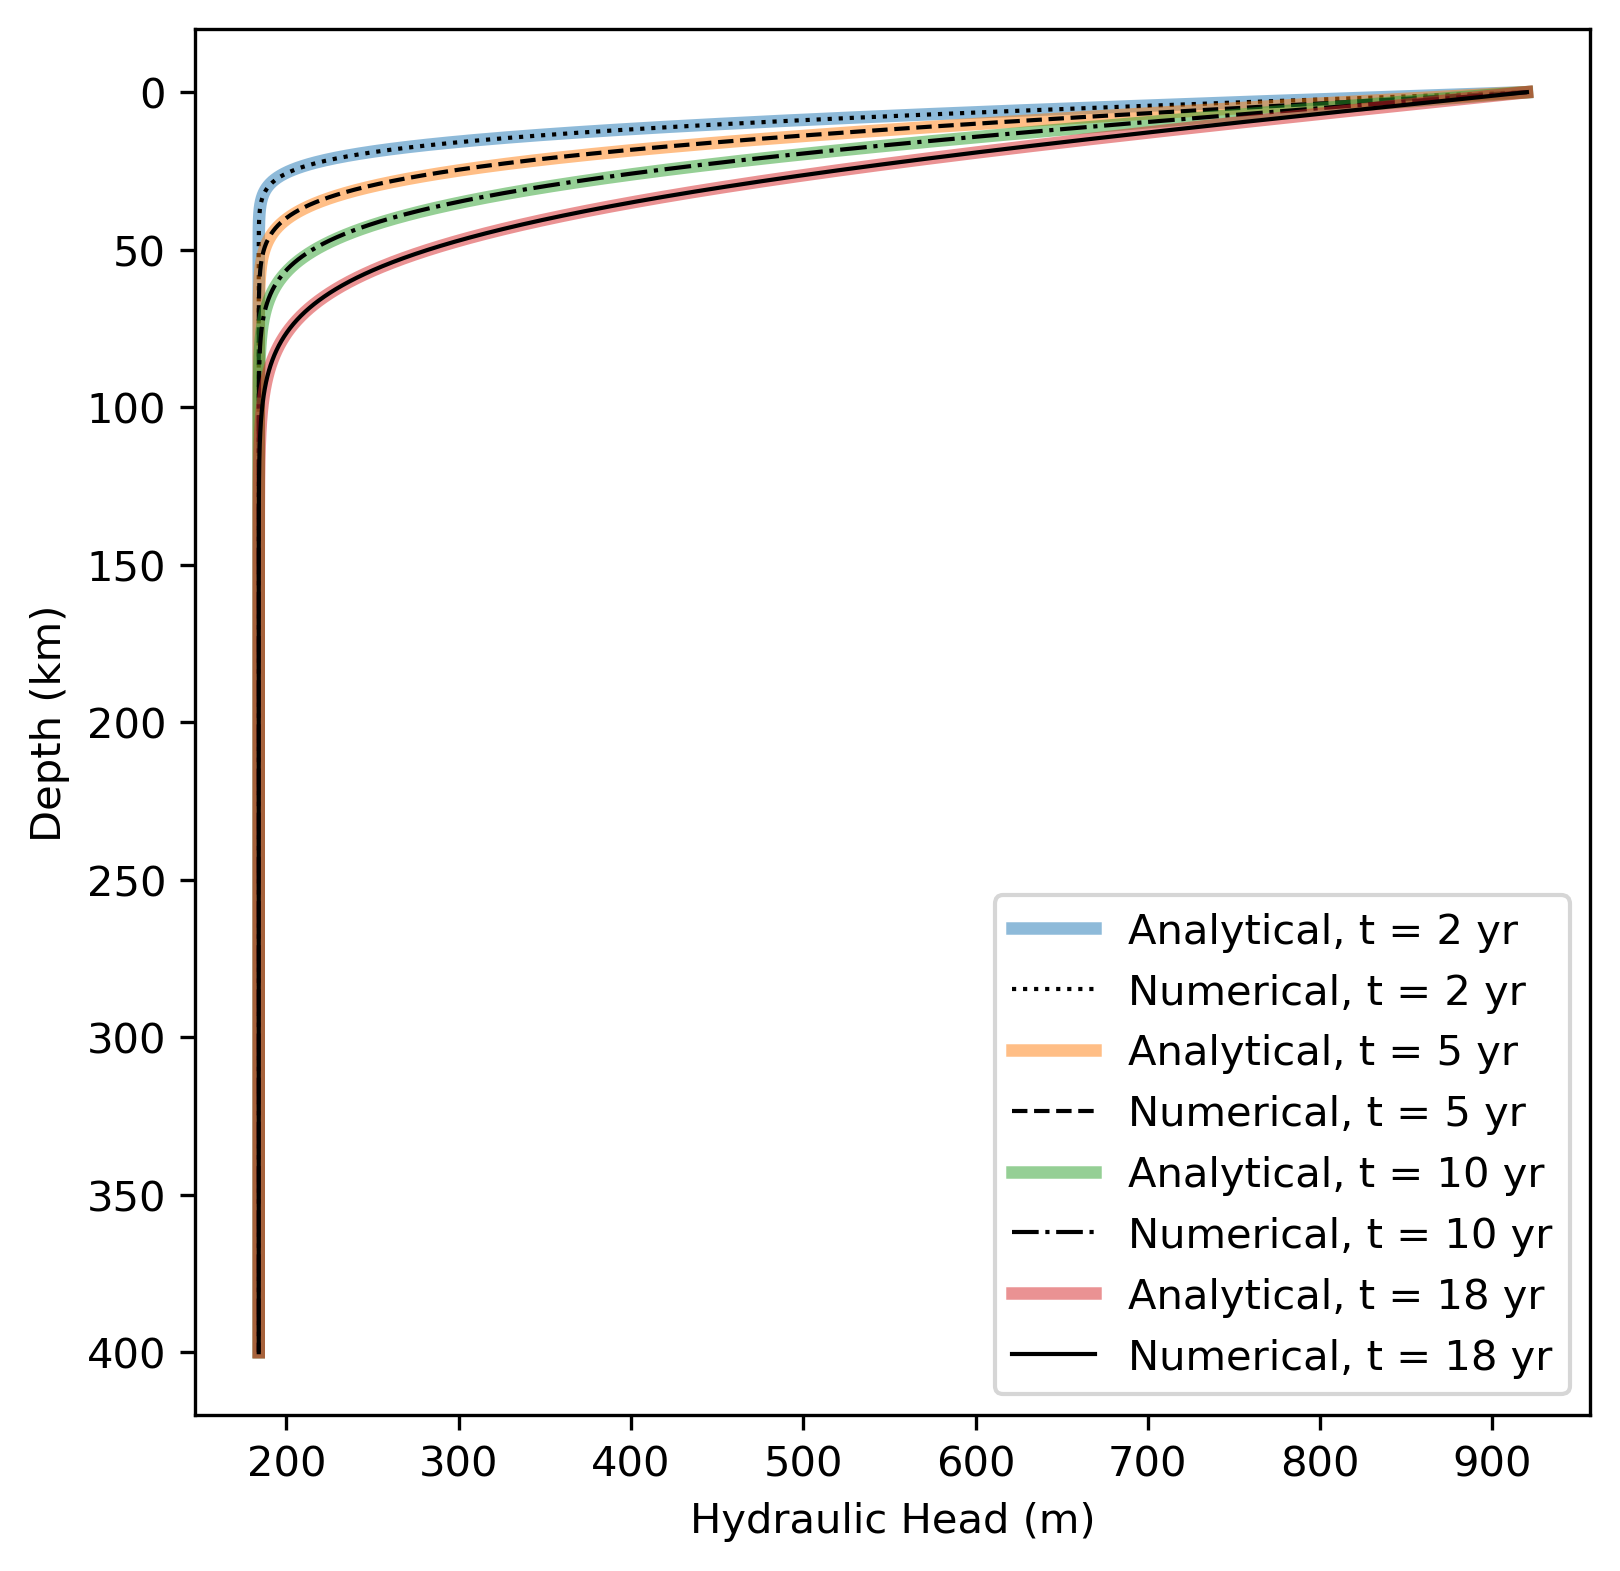

In [8]:
fig = plt.figure(figsize=(6,6),dpi=300)
ax = plt.subplot(1,1,1)
year_arr = [2,5,10,18]
line_arr = ["dotted","dashed","dashdot","solid"]
for i in range(np.size(year_arr)):
    yr = year_arr[i]
    t_second = yr*year
    i_analytical = np.argmin(np.abs(t_analytical - t_second))
    i_numerical = np.argmin(np.abs(t_numerical - t_second))
    ax.plot(h_analytical[:,i_analytical],z/1e3,lw=3,label = f"Analytical, t = {yr} yr",alpha=0.5)
    ax.plot(h_numerical[:,i_numerical],z/1e3,linestyle=line_arr[i],lw=1,color = "black",label = f"Numerical, t = {yr} yr")
    print(np.max(np.abs(h_analytical[:,i_analytical] - h_numerical[:,i_numerical])))

ax.invert_yaxis()
plt.legend()
plt.ylabel("Depth (km)")
plt.xlabel("Hydraulic Head (m)")


# Spatial Convergence

In [9]:
C_D_fixed = 0.5
dz_arr = np.array([4000,2000,1000,400,200,100])
l2_spatial_error = []

for i in range(np.size(dz_arr)):
    intSave=1
    dz_test = dz_arr[i]
    dt_test = C_D_fixed*dz_test**2/D
    nt_test = int(np.round(tf/dt_test))
    dt_test = tf/nt_test
    nz_test = int(L/dz_test) + 1
    z_test = np.arange(0, L+dz_test, dz_test)
    sfc,h_ntest = run_model(intSave,xi,k,S,dt_test,dz_test,L,nt_test,0,deltaH,alpha)
    h_atest = analytical_step(z_test,tf,alpha,xi,D)

    l2error = np.linalg.norm(h_atest - h_ntest[:,-1]) / np.linalg.norm(h_atest)
    l2_spatial_error.append(l2error)


# Temporal Convergence

In [10]:
dz_fixed = 500

dt_truth = 500
nt_truth = int(np.round(tf/dt_truth))
dt_truth = tf/nt_truth

dt_multipliers = np.array([512,256,128,64,32,16])
l2_temporal_error = []
C_D_temporal = []
intSave = 1
for i in range(np.size(dt_multipliers)):
    dt_test = dt_truth*dt_multipliers[i]
    print(D*dt_test/dz_fixed**2)


h_ref = run_model_memsave(intSave,xi,k,S,dt_truth,dz_fixed,L,nt_truth,0,deltaH,alpha)

for i in range(np.size(dt_multipliers)):
    print(i)
    dt_test = dt_truth*dt_multipliers[i]
    nt_test = int(np.round(tf/dt_test))
    dt_test = tf/nt_test
    C_D_temporal.append(D*dt_test/dz_fixed**2)
    h_ntest = run_model_memsave(intSave,xi,k,S,dt_test,dz_fixed,L,nt_test,0,deltaH,alpha)
    l2error = np.linalg.norm(h_ref - h_ntest) / np.linalg.norm(h_ref)
    l2_temporal_error.append(l2error)



1.004544
0.502272
0.251136
0.125568
0.062784
0.031392


0
1
2
3
4
5


Text(0.5, 1.0, 'Temporal Convergence (Self)')

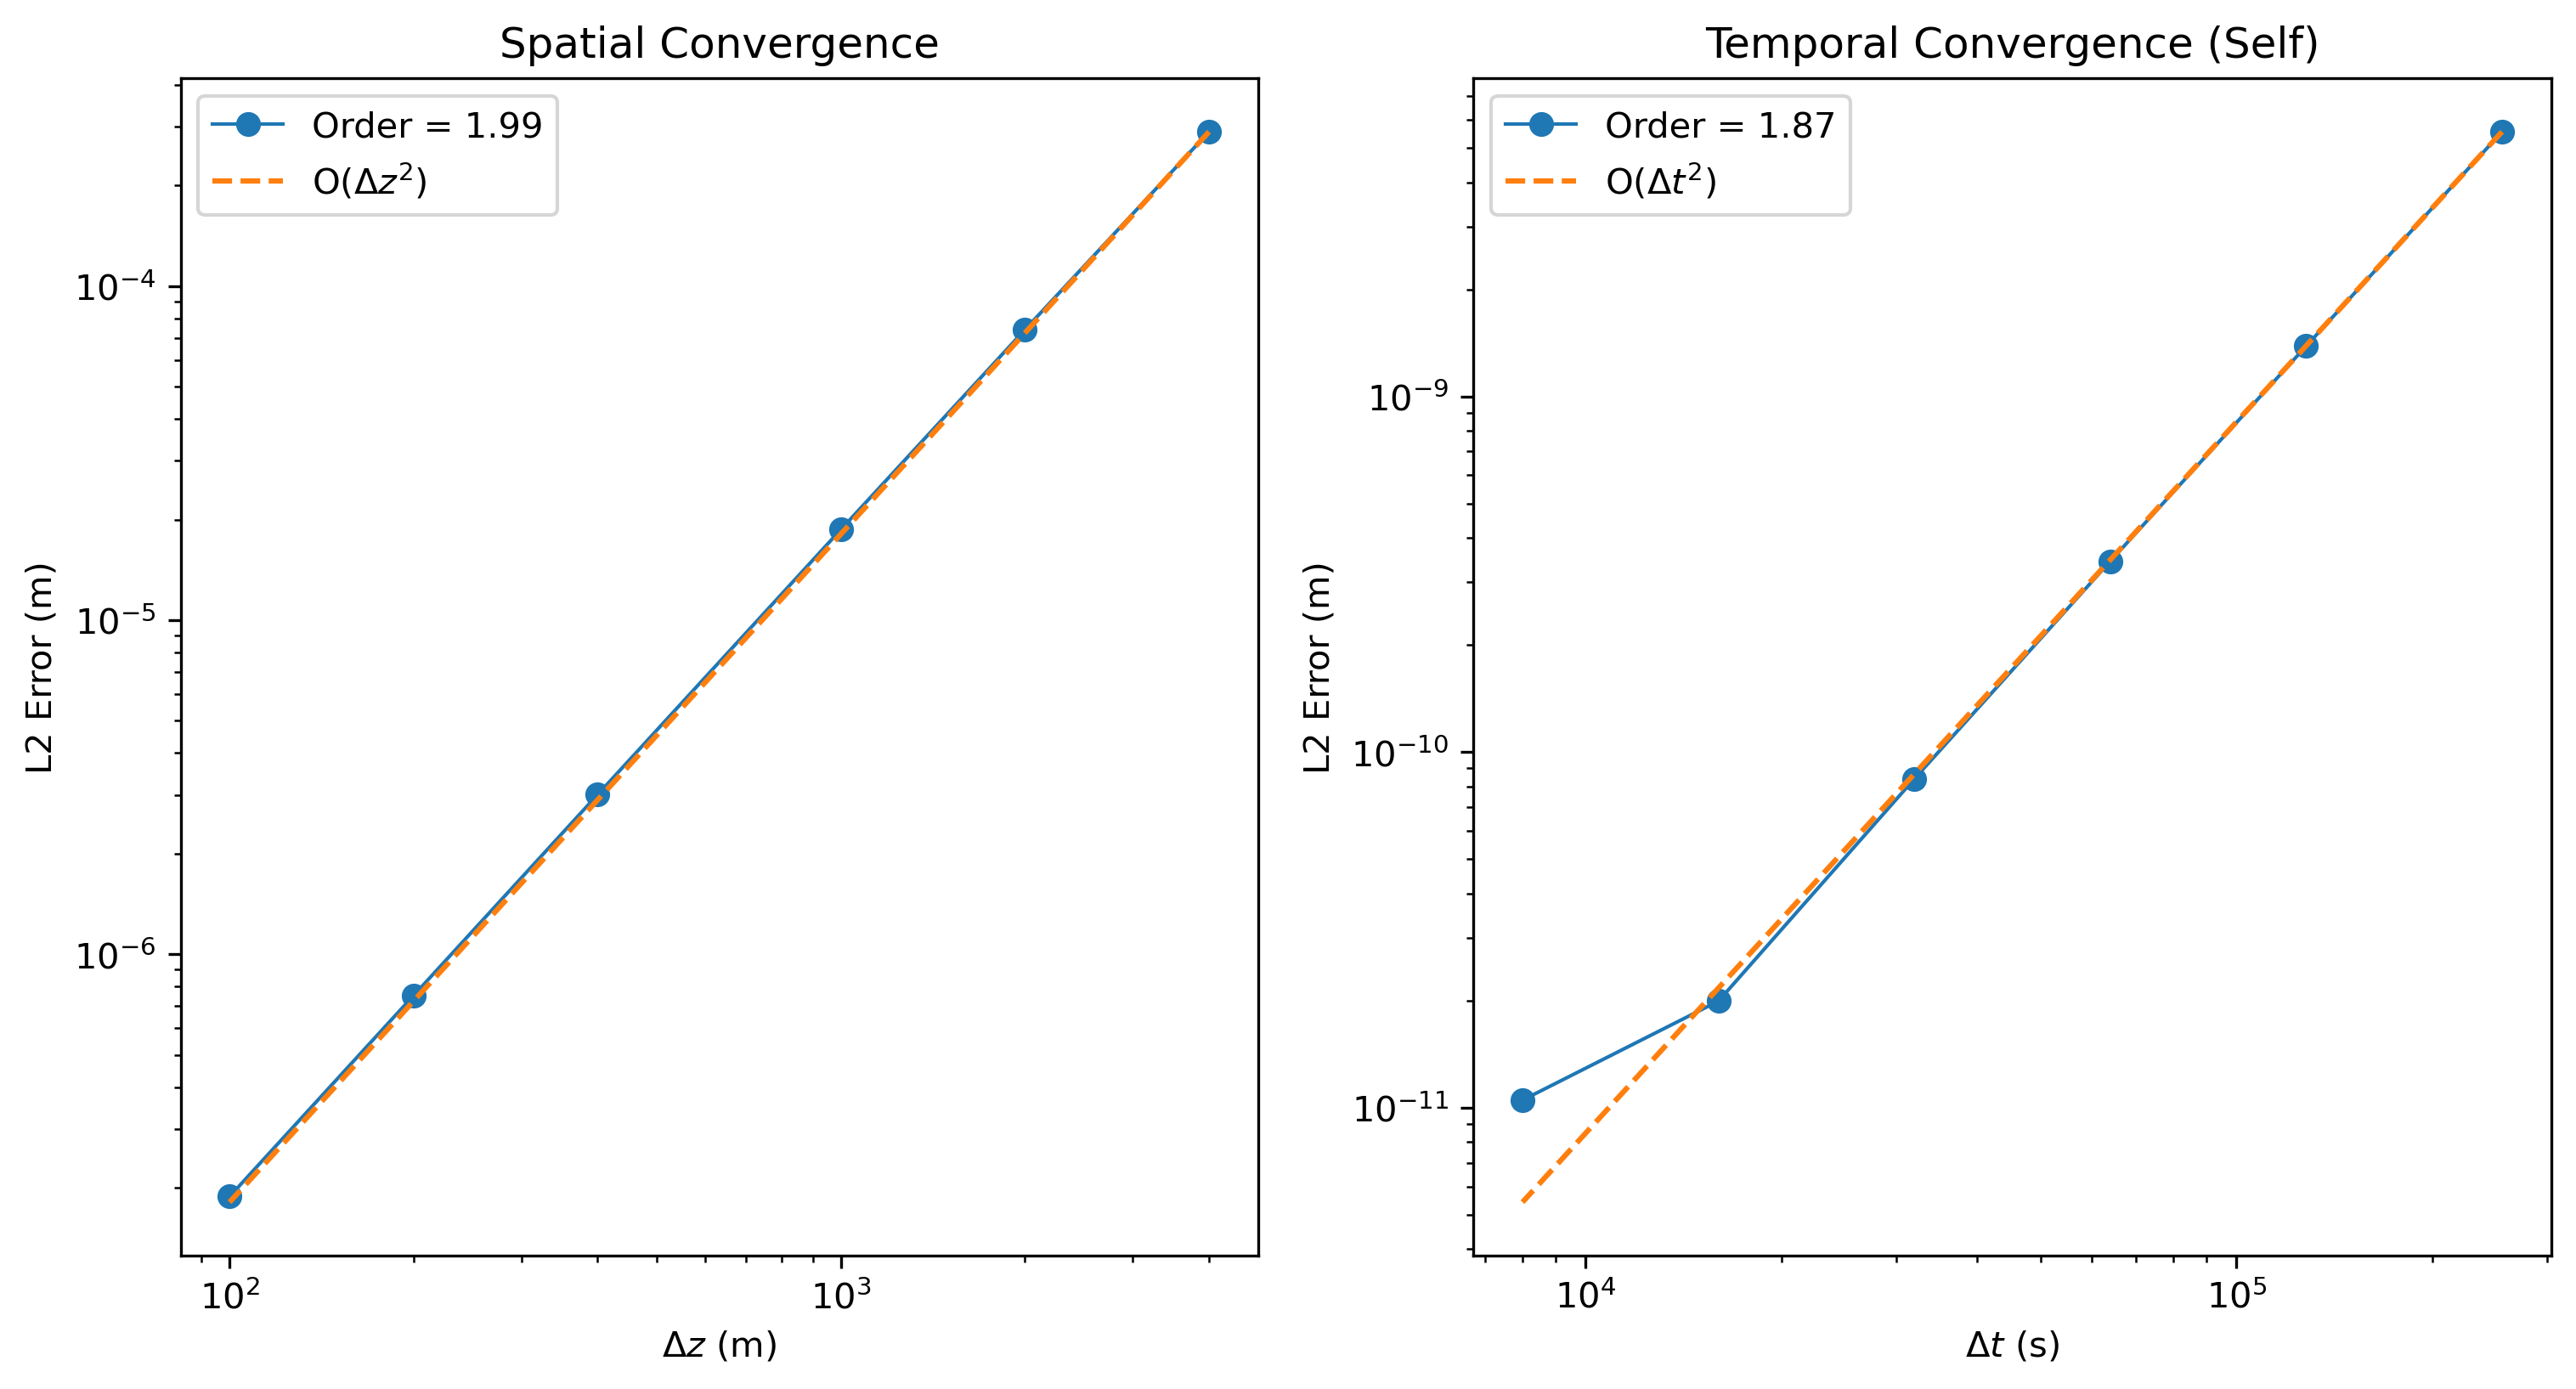

In [11]:
plt.figure(figsize=(12,6),dpi=300)
ax = plt.subplot(1,2,1)

e_ref = l2_spatial_error[0] * (dz_arr/dz_arr[0])**2

slope, intercept = np.polyfit(np.log(dz_arr), np.log(l2_spatial_error), 1)
ax.loglog(dz_arr,l2_spatial_error,"-o",lw = 1, label = f"Order = %.2f" % slope)
ax.loglog(dz_arr,e_ref,"--", label=r"O($\Delta z^2$)")
plt.legend()
plt.ylabel("L2 Error (m)")
plt.xlabel(r"$\Delta z$ (m)")
plt.title("Spatial Convergence")

ax = plt.subplot(1,2,2)
dt_arr = dt_multipliers*dt_truth

e_ref = l2_temporal_error[0] * (dt_arr/dt_arr[0])**2
slope, intercept = np.polyfit(np.log(dt_arr), np.log(l2_temporal_error), 1)
ax.loglog(dt_arr,l2_temporal_error,"-o",lw = 1, label = f"Order = %.2f" % slope)
ax.loglog(dt_arr,e_ref,"--", label=r"O($\Delta t^2$)")
plt.legend()
plt.ylabel("L2 Error (m)")
plt.xlabel(r"$\Delta t$ (s)")
plt.title("Temporal Convergence (Self)")
